1. Health Expectation

In [17]:
import seaborn as sns 
import matplotlib.pylab as plt

In [61]:
df = sns.load_dataset('healthexp')
df .head()
df.info()
df.nunique()

<class 'pandas.DataFrame'>
RangeIndex: 274 entries, 0 to 273
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             274 non-null    int64  
 1   Country          274 non-null    str    
 2   Spending_USD     274 non-null    float64
 3   Life_Expectancy  274 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 8.7 KB


Year                51
Country              6
Spending_USD       274
Life_Expectancy    118
dtype: int64

### Descrition des variables

|Variable Continue | Variable discrète |
|------------------|-------------------|
|Spending_USD      | Year              |
|Life_Expectance   | Country           |

### Analyse de la variable Country

Country
France           0.13
Great Britain    0.16
Canada           0.16
Germany          0.18
Japan            0.19
USA              0.19
Name: proportion, dtype: float64


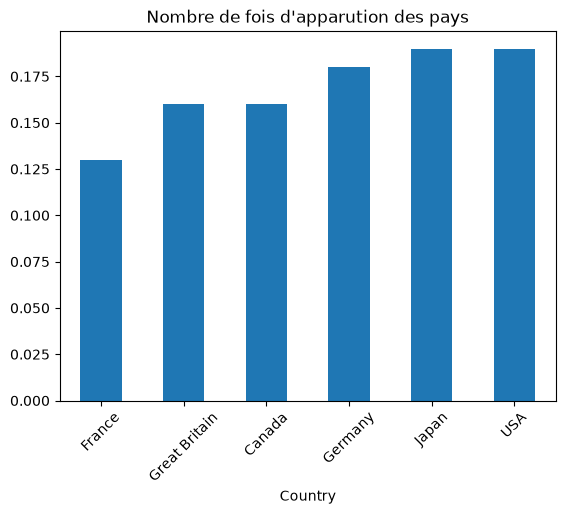

<Axes: xlabel='Country', ylabel='count'>

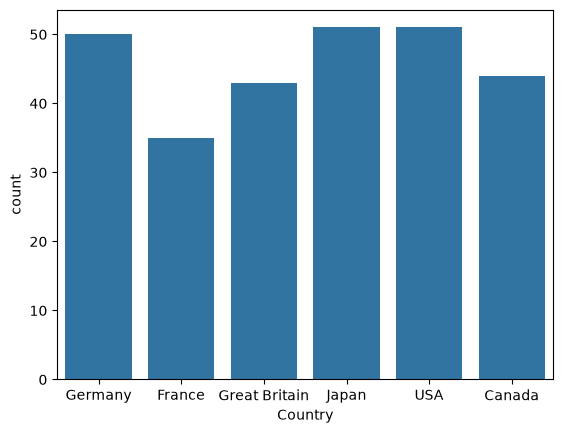

In [73]:
country =df['Country'].value_counts(normalize=True, ascending=True).round(2)
print(country)
country.plot(kind='bar', rot=45)
plt.title("Nombre de fois d'apparution des pays")
plt.show()
sns.countplot(df, x='Country')

### Analyse de la variable spending_usd

* La France, les USA, le Canade, le Japon, Allema,gne et la grande bretagne, ont depenser ensemble en moyenne 2789 USD par an de 1970 à 2020
* Avec un ecart type de 2194 USD
* La plus faible depense : 123 USD ! hum quel pays? et Quelle Année?
* Le plus élévé: ...

count      274.000000
mean      2789.338905
std       2194.939785
min        123.993000
25%       1038.357000
50%       2295.578000
75%       4055.610000
max      11859.179000
Name: Spending_USD, dtype: float64


<Axes: xlabel='Spending_USD'>

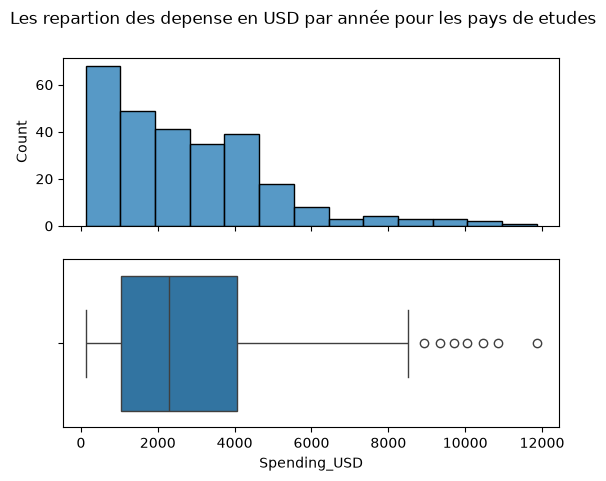

In [82]:
spending_usd = df['Spending_USD']
print(spending_usd.describe())

# Annalyse visuelle
fig, ax = plt.subplots(2, 1, sharex=True)
plt.suptitle('Les repartion des depense en USD par année pour les pays de etudes')
sns.histplot(df, x='Spending_USD', ax=ax[0])
sns.boxplot(df, x='Spending_USD', ax=ax[1])

### Analyse de la variable spending_usd

* La France, les USA, le Canade, le Japon, Allema,gne et la grande bretagne, la durée de vie moyenne a été de 78 ans entre de 1970 à 2020
* Avec un ecart type de 3 ans
* La plus faible depense : 70 ans!
* Le plus élévé: ...

count    274.000000
mean      77.909489
std        3.276263
min       70.600000
25%       75.525000
50%       78.100000
75%       80.575000
max       84.700000
Name: Life_Expectancy, dtype: float64


<Axes: xlabel='Life_Expectancy'>

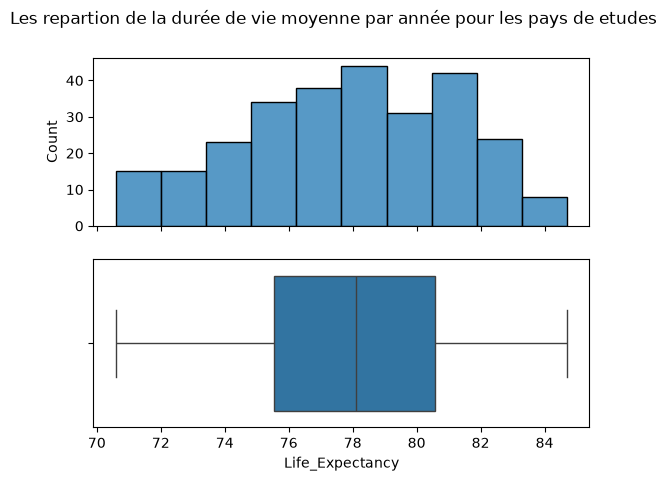

In [85]:
spending_usd = df['Life_Expectancy']
print(spending_usd.describe())

# Annalyse visuelle
fig, ax = plt.subplots(2, 1, sharex=True)
plt.suptitle('Les repartion de la durée de vie moyenne par année pour les pays de etudes')
sns.histplot(df, x='Life_Expectancy', ax=ax[0])
sns.boxplot(df, x='Life_Expectancy', ax=ax[1])


### Analyse de evolution de la durée de vie a travers année

<Axes: xlabel='Year', ylabel='Life_Expectancy'>

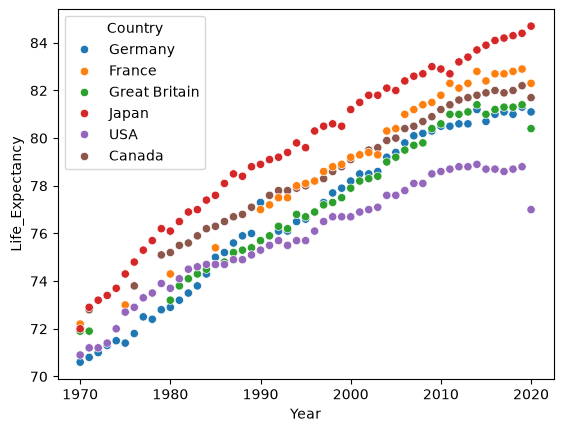

In [29]:
sns.scatterplot(df, x='Year', y='Life_Expectancy', hue='Country')

### Annalyse des depense en santé pour allemangne et la grande bretagne

<Axes: xlabel='Year', ylabel='Life_Expectancy'>

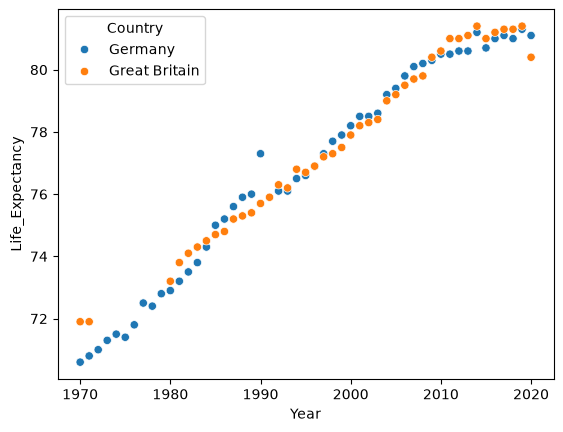

In [34]:
sub_df = df.query("Country in ['Germany', 'Great Britain']")
sns.scatterplot(sub_df, x='Year', y='Life_Expectancy', hue='Country')

* Les depense depence en sante de allemagne et la grandre bretagne sont très similaire 

### Annalyse de la variable life expectancy propre a chaque pays

In [42]:
life = df.groupby('Country')['Life_Expectancy']
life.describe()

,count,mean,std,min,25%,50%,75%,max
Country,,,,,,,,
Canada,44.0,78.706818,2.502222,72.8,76.775,78.7,80.975,82.2
France,35.0,79.565714,2.862120,72.2,78.050,79.4,82.200,82.9
Germany,50.0,76.726000,3.473915,70.6,73.575,77.1,80.175,81.3
Great Britain,43.0,77.620930,2.827548,71.9,75.350,77.5,80.400,81.4
Japan,51.0,79.554902,3.547242,72.0,76.950,79.8,82.650,84.7
USA,51.0,75.843137,2.336258,70.9,74.550,75.7,77.950,78.9


<Axes: xlabel='Country', ylabel='Life_Expectancy'>

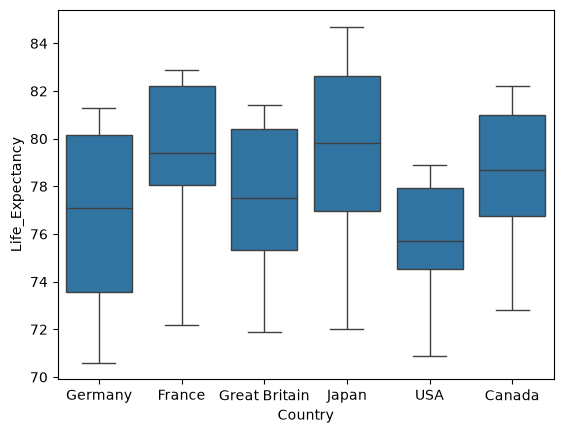

In [39]:
sns.boxplot(df, x='Country',  y='Life_Expectancy')

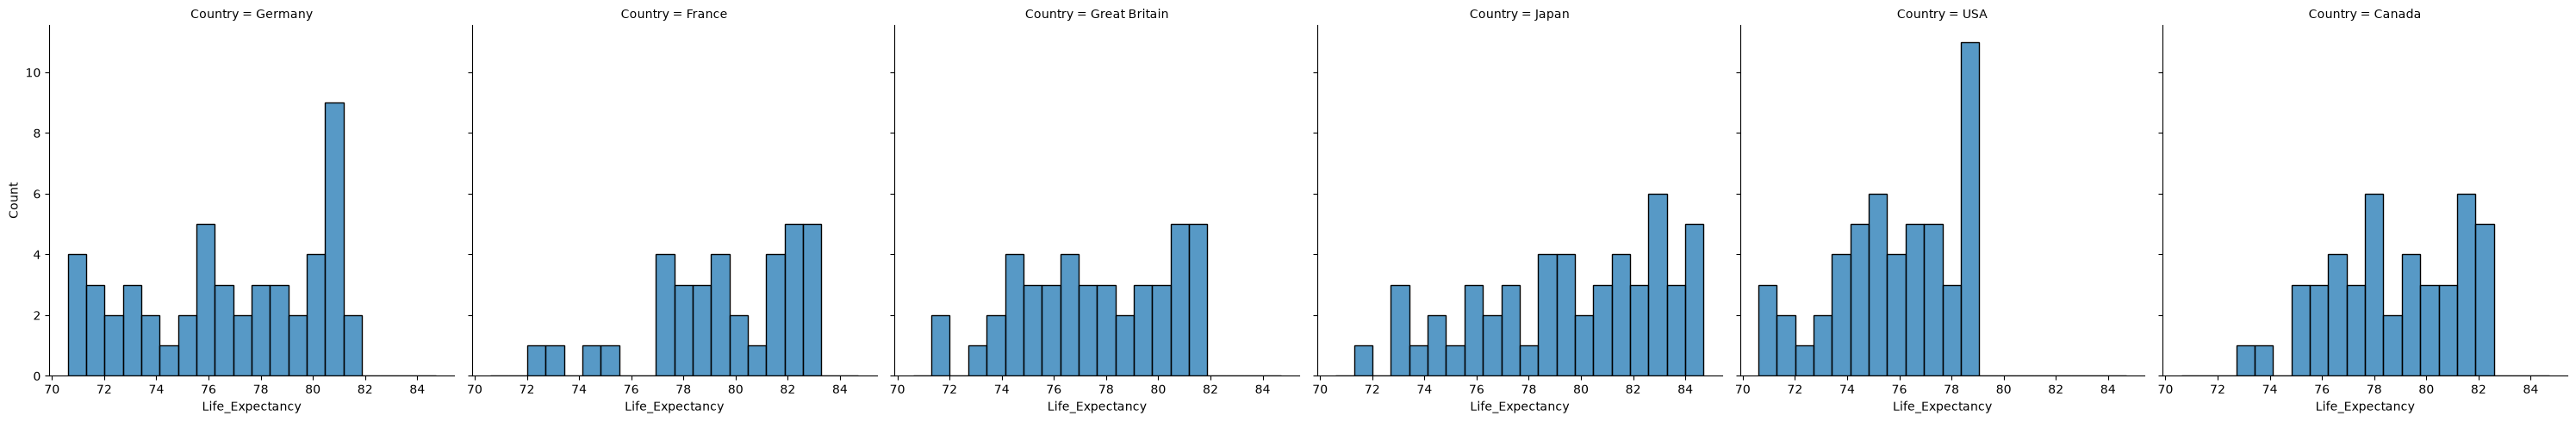

In [86]:
sns.displot(df,  x='Life_Expectancy', col='Country', bins= 20)

### La relation entre la durée de vie et les depense en santée au USA entre 2000 et 2020

* La valuer aberante est cosé pas le COVID 19.

<Axes: xlabel='Spending_USD', ylabel='Life_Expectancy'>

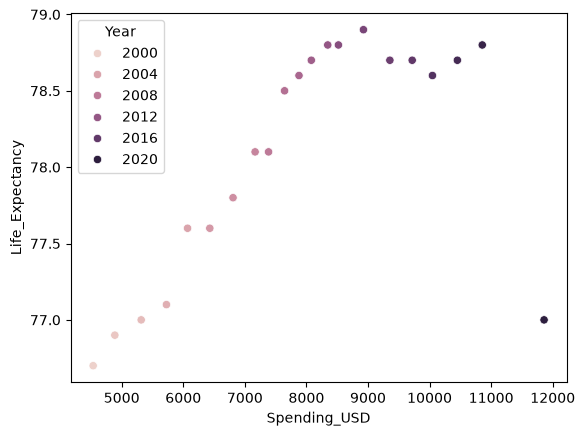

In [89]:
sub_df = df.query("Country =='USA' and Year >= 2000")

sns.scatterplot(sub_df,  x='Spending_USD', y='Life_Expectancy', hue='Year')

Plus on insvestir dans la santer plus experance de vie augmente.

In [57]:
sub_df[sub_df['Spending_USD'] > 11000]

,Year,Country,Spending_USD,Life_Expectancy
273,2020,USA,11859.179,77.0
